# Model II
## Rozpoznawanie instrumentów za pomocą konwolucji (niezależne sieci dla każdej klasy instrumentu)

### Biblioteki

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

from model import MultiInstrumentCNN
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [10]:
epochs = 3
patience = 3
batch_size = 8
learning_rate = 0.0005

dropout2 = 0.1
dropout3 = 0.3

threshold = 0.8

In [11]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [12]:
device = get_device()

model = MultiInstrumentCNN(num_instruments=len(INSTRUMENTS), dropout2=dropout2, dropout3=dropout3).to(device)

criterion = nn.MultiLabelSoftMarginLoss()

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [13]:
start_time = time.perf_counter()

model, history, best_epoch, best_val_loss = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=epochs,
    patience=patience,
    model_name="cnn2_weights.pth"
)

training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/3 | Train loss: 0.6026 | Val loss: 0.5258
Epoka 2/3 | Train loss: 0.5183 | Val loss: 0.4943
Epoka 3/3 | Train loss: 0.4867 | Val loss: 0.4505
Najlepsza epoka: 3
Najlepszy validation loss: 0.4505
Czas treningu: 10.50 min


In [ ]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.672,0.447,0.655,0.941,0.722,0.448,0.615
1,0.552,0.393,0.655,0.999,0.380,0.369,0.236
2,0.066,0.464,0.154,1.000,0.052,0.368,0.016
3,0.251,0.533,0.524,0.986,0.070,0.454,0.663
4,0.629,0.473,0.453,0.975,0.634,0.417,0.229
5,0.928,0.547,0.375,0.001,0.072,0.449,0.671
6,0.634,0.516,0.576,0.000,0.991,0.358,0.512
7,0.153,0.528,0.649,0.921,0.032,0.457,0.576


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0,0,0,1,0,0,0
1,0,0,0,1,0,0,0
2,0,0,0,1,0,0,0
3,0,0,0,1,0,0,0
4,0,0,0,1,0,0,0
5,1,0,0,0,0,0,0
6,0,0,0,0,1,0,0
7,0,0,0,1,0,0,0


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,1,1
1,0,1,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,1,0,1,0,0,1
4,1,0,1,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,1
7,0,1,1,1,0,1,1


In [14]:
model.eval()

all_predictions = []
all_labels = []

val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)

        loss = criterion(logits, y)
        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_micro = f1_score(
    all_labels,
    all_predictions,
    average="micro",
    zero_division=0
)

f1_macro = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Micro-F1: {f1_micro:.4f}")
print(f"Macro-F1: {f1_macro:.4f}")

Validation loss: 0.4505
Micro-F1: 0.5122
Macro-F1: 0.4166


In [15]:
results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / "porownanie_eksperymentow.csv"

experiment = pd.DataFrame([{
    "Model": "CNN2",
    "Batch size": batch_size,
    "Learning rate": learning_rate,
    "Dropout 2": dropout2,
    "Dropout 3": dropout3,
    "Threshold": threshold,
    "Best epoch": best_epoch,
    "Best val loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    "Training time [min]": training_time / 60
}])

if results_file.exists():
    experiment.to_csv(
        results_file,
        mode="a",
        header=False,
        index=False
    )
else:
    experiment.to_csv(results_file, index=False)

experiment

,Model,Batch size,Learning rate,Dropout 2,Dropout 3,Threshold,Best epoch,Best val loss,Micro-F1,Macro-F1,Training time [min]
0,CNN2,8,0.0005,0.1,0.3,0.8,3,0.450512,0.512189,0.416645,10.498718


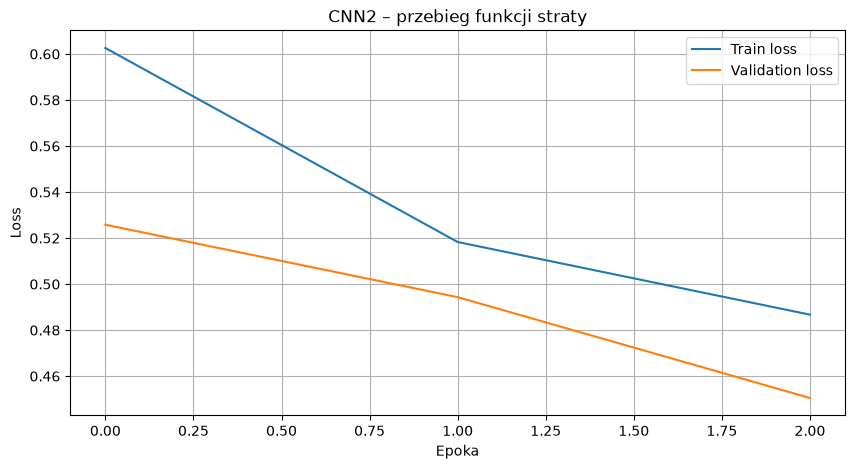

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("CNN2 – przebieg funkcji straty")

plt.legend()
plt.grid()
plt.show()

In [ ]:
f1_per_instrument = f1_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

precision_per_instrument = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall_per_instrument = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics_df = pd.DataFrame({
    "Instrument": instrument_names,
    "Precision": precision_per_instrument,
    "Recall": recall_per_instrument,
    "F1-score": f1_per_instrument
})

metrics_df

,Instrument,Precision,Recall,F1-score
0,Gitara akustyczna,0.940476,0.294045,0.448015
1,Saksofon altowy,0.750000,0.021398,0.041609
2,Fortepian,0.747967,0.115869,0.200654
3,Perkusja,0.995885,0.874699,0.931366
4,Gitara basowa,0.946945,0.714806,0.814661
5,Flet,0.750000,0.004280,0.008511
6,Sekcja smyczkowa,0.988142,0.309789,0.471698


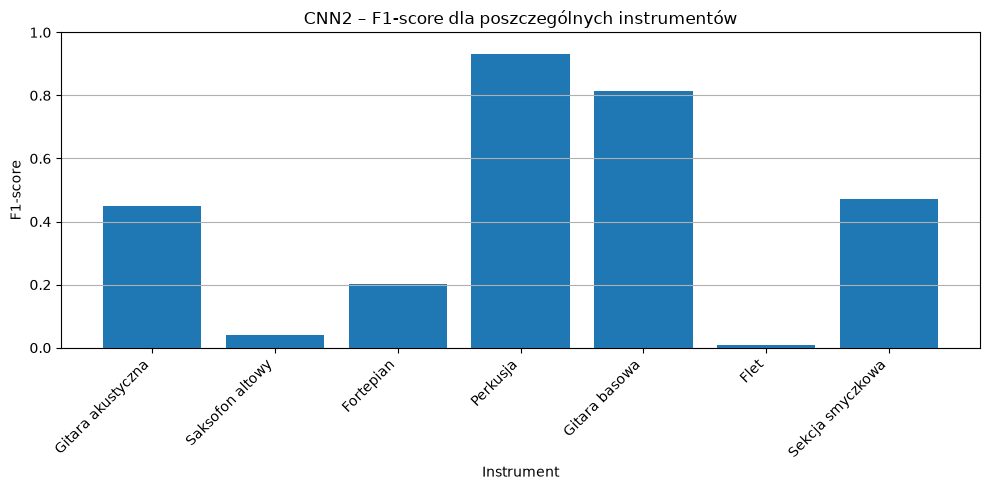

In [18]:
plt.figure(figsize=(10, 5))

plt.bar(instrument_names, f1_per_instrument)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("CNN2 – F1-score dla poszczególnych instrumentów")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()